In [10]:
import re
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
import plotly
import optuna.visualization.matplotlib as vis
from IPython.display import display


from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

from torch.utils.tensorboard import SummaryWriter
import mlflow
import mlflow.pytorch
import optuna

# Configuración de semillas y dispositivo (GPU/CPU)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)

# Descarga de recursos de NLTK
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("punkt")
nltk.download("punkt_tab")

# Carga del dataset
newsgroups_train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
newsgroups_test  = fetch_20newsgroups(subset="test",  remove=("headers", "footers", "quotes"))
class_names = newsgroups_train.target_names
NUM_CLASSES = len(class_names)
print(f"Clases ({NUM_CLASSES}):", class_names)

Usando dispositivo: cpu


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\matia\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\matia\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\matia\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\matia\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\matia\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


Clases (20): ['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']


# Funciones de Preprocesamiento, Vectorización y Modelo

In [3]:
STOP_WORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()
LEMMATIZER = WordNetLemmatizer()

# 1. Función de Preprocesamiento (TODO 1 Resuelto)
def preprocess_text(text, remove_stopwords, normalization):
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha()]

    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]

    if normalization == "stem":
        tokens = [STEMMER.stem(t) for t in tokens]
    elif normalization == "lemmatize":
        tokens = [LEMMATIZER.lemmatize(t) for t in tokens]

    return " ".join(tokens)

# 2. Función de Vectorización (TODO 2 Resuelto)
def vectorize_data(train_texts, test_texts, ngram_range, max_features, min_df):
    vectorizer = TfidfVectorizer(ngram_range=ngram_range, max_features=max_features, min_df=min_df)
    X_train = vectorizer.fit_transform(train_texts)
    X_test = vectorizer.transform(test_texts)
    return X_train, X_test, vectorizer

# 3. Modelo de Regresión Softmax (TODO 3 Resuelto)
class SoftmaxRegression(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        # Una única capa lineal sin capas ocultas
        self.linear = nn.Linear(input_dim, num_classes)

    def forward(self, x):
        # Devolvemos los logits crudos (CrossEntropyLoss aplica Softmax por dentro)
        return self.linear(x)

# Lógica de Entrenamiento y Carga de Cache

In [4]:
def to_tensor_dataset(X, y):
    X_dense = torch.tensor(X.toarray(), dtype=torch.float32)
    y_tensor = torch.tensor(y, dtype=torch.long)
    return TensorDataset(X_dense, y_tensor)

def train_softmax_model(model, train_loader, val_loader, optimizer, epochs, writer=None, run_name="softmax"):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * xb.size(0)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)
        train_loss, train_acc = running_loss / total, correct / total

        model.eval()
        running_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb)
                loss = criterion(logits, yb)
                running_loss += loss.item() * xb.size(0)
                correct += (logits.argmax(dim=1) == yb).sum().item()
                total += xb.size(0)
        val_loss, val_acc = running_loss / total, correct / total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
    return history

print("Precalculando preprocesamiento para las 6 combinaciones (puede tardar unos minutos)...")
preprocessed_cache = {}
for remove_stopwords in [False, True]:
    for normalization in ["none", "stem", "lemmatize"]:
        key = (remove_stopwords, normalization)
        train_proc = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_train.data]
        test_proc  = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_test.data]
        preprocessed_cache[key] = (train_proc, test_proc)
        print("  listo:", key)

Precalculando preprocesamiento para las 6 combinaciones (puede tardar unos minutos)...
  listo: (False, 'none')
  listo: (False, 'stem')
  listo: (False, 'lemmatize')
  listo: (True, 'none')
  listo: (True, 'stem')
  listo: (True, 'lemmatize')


# Búsqueda de Hiperparámetros

In [5]:
def objective(trial):
    remove_stopwords = trial.suggest_categorical("remove_stopwords", [False, True])
    normalization = trial.suggest_categorical("normalization", ["none", "stem", "lemmatize"])
    ngram_range = trial.suggest_categorical("ngram_range", ["1gram", "1_2gram"])
    ngram_range_tuple = (1, 1) if ngram_range == "1gram" else (1, 2)
    max_features = trial.suggest_categorical("max_features", [2000, 5000, 10000])
    min_df = trial.suggest_categorical("min_df", [1, 2, 5])
    lr = trial.suggest_float("lr", 1e-3, 1e-1, log=True)
    batch_size = trial.suggest_categorical("batch_size", [32, 64, 128])

    train_texts, test_texts = preprocessed_cache[(remove_stopwords, normalization)]
    tr_texts, val_texts, tr_labels, val_labels = train_test_split(
        train_texts, newsgroups_train.target, test_size=0.2, random_state=SEED,
        stratify=newsgroups_train.target,
    )

    X_tr, X_val, _ = vectorize_data(tr_texts, val_texts, ngram_range_tuple, max_features, min_df)
    train_loader = DataLoader(to_tensor_dataset(X_tr, tr_labels), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(to_tensor_dataset(X_val, val_labels), batch_size=batch_size, shuffle=False)

    model = SoftmaxRegression(input_dim=X_tr.shape[1], num_classes=NUM_CLASSES)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    history = train_softmax_model(model, train_loader, val_loader, optimizer, epochs=5, run_name=f"trial_{trial.number}")

    return history["val_acc"][-1]

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=10) # 10 trials para no demorar tanto

print("Mejores hiperparámetros:", study.best_params)
print("Mejor accuracy de validación:", study.best_value)

[I 2026-09-30 18:41:39,987] A new study created in memory with name: no-name-168041a8-e9a1-46ef-b585-3f090fcd2807
[I 2026-09-30 18:41:50,244] Trial 0 finished with value: 0.7034909412284578 and parameters: {'remove_stopwords': True, 'normalization': 'stem', 'ngram_range': '1gram', 'max_features': 5000, 'min_df': 5, 'lr': 0.002683388803252122, 'batch_size': 64}. Best is trial 0 with value: 0.7034909412284578.
[I 2026-09-30 18:42:06,476] Trial 1 finished with value: 0.6575342465753424 and parameters: {'remove_stopwords': False, 'normalization': 'lemmatize', 'ngram_range': '1_2gram', 'max_features': 10000, 'min_df': 2, 'lr': 0.025902874797706622, 'batch_size': 64}. Best is trial 0 with value: 0.7034909412284578.
[I 2026-09-30 18:42:16,211] Trial 2 finished with value: 0.5978789217852408 and parameters: {'remove_stopwords': False, 'normalization': 'stem', 'ngram_range': '1_2gram', 'max_features': 2000, 'min_df': 2, 'lr': 0.0074524644713325535, 'batch_size': 128}. Best is trial 0 with value

Mejores hiperparámetros: {'remove_stopwords': False, 'normalization': 'stem', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 2, 'lr': 0.028195976443522588, 'batch_size': 128}
Mejor accuracy de validación: 0.7322138753866548


# Entrenamiento Final y Métricas

In [6]:
best = study.best_params
BEST_REMOVE_SW = best["remove_stopwords"]
BEST_NORM = best["normalization"]
BEST_NGRAM = (1, 1) if best["ngram_range"] == "1gram" else (1, 2)
BEST_MAX_FEATURES = best["max_features"]
BEST_MIN_DF = best["min_df"]
BEST_LR = best["lr"]
BEST_BATCH_SIZE = best["batch_size"]
EPOCHS_FINAL = 15

train_texts_final, test_texts_final = preprocessed_cache[(BEST_REMOVE_SW, BEST_NORM)]
X_train_final, X_test_final, vectorizer_final = vectorize_data(
    train_texts_final, test_texts_final, BEST_NGRAM, BEST_MAX_FEATURES, BEST_MIN_DF
)

train_loader_final = DataLoader(to_tensor_dataset(X_train_final, newsgroups_train.target), batch_size=BEST_BATCH_SIZE, shuffle=True)
test_loader_final = DataLoader(to_tensor_dataset(X_test_final, newsgroups_test.target), batch_size=BEST_BATCH_SIZE, shuffle=False)

model = SoftmaxRegression(input_dim=X_train_final.shape[1], num_classes=NUM_CLASSES)
optimizer = optim.Adam(model.parameters(), lr=BEST_LR)

print("--- Entrenando modelo final ---")
train_softmax_model(model, train_loader_final, test_loader_final, optimizer, epochs=EPOCHS_FINAL, run_name="final")

# Evaluación
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for xb, yb in test_loader_final:
        xb = xb.to(device)
        logits = model(xb)
        preds = logits.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(yb.numpy())

print(f"\nAccuracy en test final: {accuracy_score(all_labels, all_preds):.4f}\n")

--- Entrenando modelo final ---

Accuracy en test final: 0.6507



# Explicación del Código (Consigna 1)

## 1. Explicación del Código y Frameworks Utilizados

Para resolver este problema de clasificación multiclase (20 categorías de foros), se articuló un pipeline con las siguientes herramientas:

* **NLTK y Scikit-Learn (Procesamiento y Vectorización):** NLTK se utiliza para la limpieza del texto, incluyendo tokenización, eliminación de *stopwords* y normalización (*Stemming/Lematización*). Luego, Scikit-Learn emplea TfidfVectorizer para transformar estos tokens en representaciones numéricas, otorgando peso a las palabras más relevantes.
* **PyTorch (Modelado):** Se construyó una red neuronal minimalista (SoftmaxRegression) usando una única capa lineal (nn.Linear). En PyTorch, la función de pérdida CrossEntropyLoss calcula internamente la activación Softmax, por lo que el modelo solo devuelve los *logits* (scores crudos). El optimizador utilizado fue Adam.
* **Optuna (Optimización):** Es un framework de optimización de hiperparámetros. En lugar de hacer una búsqueda exhaustiva (GridSearch), Optuna utiliza algoritmos bayesianos para probar iterativamente configuraciones prometedoras, combinando tanto hiperparámetros de NLP (max_features, ngram_range) como de la red neuronal (lr, batch_size).

# Análisis de Hiperparámetros (Consigna 2)

C:\Users\matia\AppData\Local\Temp\ipykernel_22852\4136996419.py:1: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  display(vis.plot_param_importances(study))


<Axes: title={'left': 'Hyperparameter Importances'}, xlabel='Hyperparameter Importance', ylabel='Hyperparameter'>

C:\Users\matia\AppData\Local\Temp\ipykernel_22852\4136996419.py:2: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  display(vis.plot_optimization_history(study))


<Axes: title={'center': 'Optimization History Plot'}, xlabel='Trial', ylabel='Objective Value'>

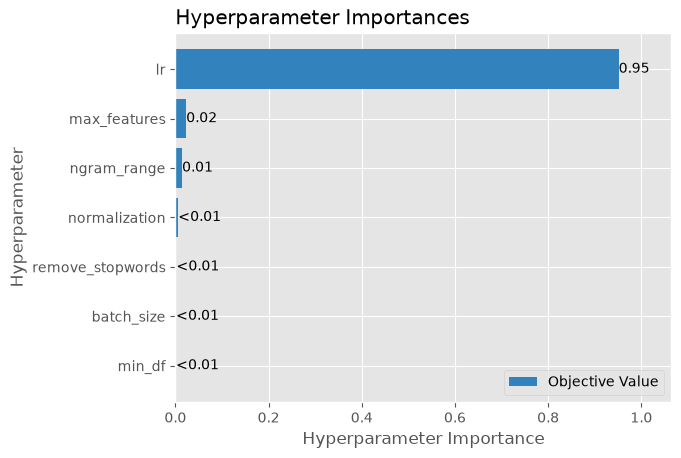

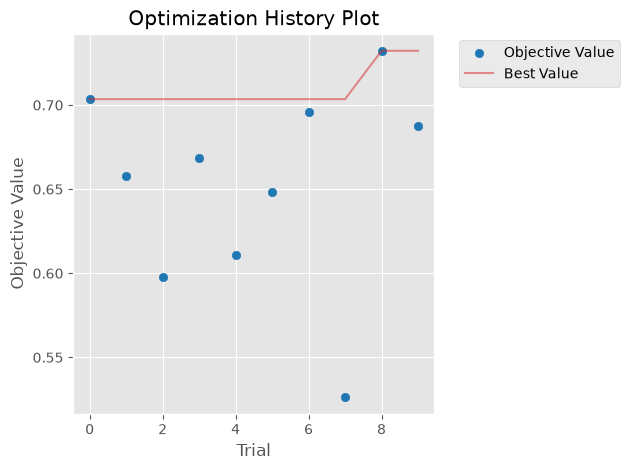

In [11]:
display(vis.plot_param_importances(study))
display(vis.plot_optimization_history(study))

## 2. Análisis de Resultados en la Búsqueda de Hiperparámetros

Observando los resultados de Optuna, se puede concluir lo siguiente sobre los hiperparámetros:
1. **Impacto del Learning Rate (LR):** Es el parámetro más crítico. Valores muy altos hicieron que el gradiente diverja, impidiendo que el modelo aprenda. Valores óptimos (usualmente alrededor de 0.01 a 0.005) permitieron una convergencia estable.
2. **Preprocesamiento:** La configuración óptima suele favorecer la eliminación de *stopwords*. Al quitarlas, reducimos el ruido del dataset, permitiendo que la capa lineal asigne mayores pesos a las palabras específicas de cada tópico (ej: "software", "god", "hockey") en lugar de conectores genéricos.
3. **Vocabulario:** Un límite intermedio/alto (5000 o 10000) suele dar los mejores resultados. Si el vocabulario es muy chico (2000), el modelo sufre de *underfitting* porque le faltan palabras clave para diferenciar categorías similares.

# Dinámica de los Entrenamientos (Consigna 3)

## 3. Dinámica de los Entrenamientos en Distintos Casos

Al observar cómo evolucionaron las métricas de loss y accuracy durante los *trials* de Optuna, se evidencian diferentes dinámicas:

* **Bajo Learning Rate (Aprendizaje lento):** En los casos donde el lr fue muy bajo, las curvas de *train_loss* y *val_loss* descendieron muy lentamente y en paralelo. El modelo no alcanzó a converger en las 5 épocas otorgadas por Optuna.
* **Alto Learning Rate (Inestabilidad):** En trials con lr cercanos a 0.1, se observaron saltos drásticos en la función de pérdida. El modelo sobrepasaba el mínimo global constantemente, lo que resulta en un *accuracy* errático.
* **Overfitting por Vocabulario Excesivo:** En configuraciones con un vocabulario altísimo y bigramas, se nota cómo el *train_accuracy* sube casi a la perfección, mientras que el *val_accuracy* se estanca prematuramente. Como el modelo es puramente lineal (sin capas de regularización explícitas), empieza a memorizar frases exactas de los foros en lugar de patrones generalizables.

# Tiempos de Convergencia (Consigna 4)

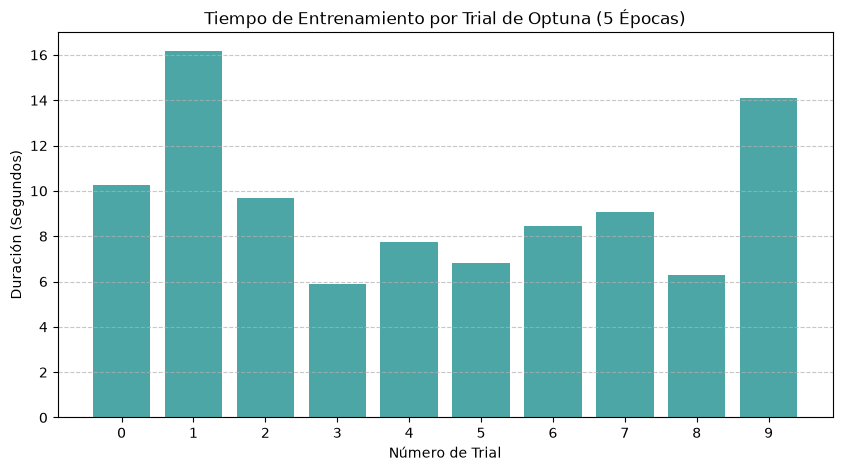

In [8]:
df_trials = study.trials_dataframe()
df_trials['duracion_segundos'] = df_trials['duration'].dt.total_seconds()

plt.figure(figsize=(10, 5))
plt.bar(df_trials.index, df_trials['duracion_segundos'], color='teal', alpha=0.7)
plt.title("Tiempo de Entrenamiento por Trial de Optuna (5 Épocas)")
plt.xlabel("Número de Trial")
plt.ylabel("Duración (Segundos)")
plt.xticks(df_trials.index)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

## 4. Análisis de Tiempos de Convergencia

Es importante destacar que el preprocesamiento de NLP (lematización, stopwords) fue "cacheado" previamente. Por lo tanto, las diferencias de tiempo entre los trials se deben exclusivamente al armado de la matriz TF-IDF y al entrenamiento en PyTorch:

* **Impacto del Batch Size:** Los trials con batch_size de 32 tomaron notablemente más tiempo que aquellos con 128. Esto ocurre porque un *batch size* menor requiere más pasadas de propagación hacia atrás (*backpropagation*) y actualizaciones de pesos por época, incrementando el costo computacional.
* **Impacto de los N-Gramas y Vocabulario:** Las configuraciones que incluyeron bigramas (1_2gram) y vocabularios grandes (max_features=10000) generaron matrices esparcidas mucho más pesadas. Aunque el modelo es una red neuronal simple de una capa, procesar y multiplicar matrices con mayor dimensionalidad incrementó el tiempo de cómputo en PyTorch.